#### To create an animation with HoloView
- Read multiple files as a single dataset using uxarray
- Create a time-varying precipitation
- save as MP4 and play
- To make your animation visible on GitHub, save animation as a .gif and play
  
Ming Ge May 2025

In [1]:
%matplotlib inline
import holoviews as hv
import numpy as np
import uxarray as ux
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs 
#hv.extension('bokeh')  # or 'matplotlib'
hv.extension('matplotlib')  
from IPython.display import Video

#### Read multiple files as a single dataset using uxarray

In [2]:
dir_data = "/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/"

flnm_grid = dir_data + "SouthAmerica.init.nc"
flnm_data = dir_data + "diag.2014-09-1*.nc"

ds = ux.open_mfdataset(flnm_grid, flnm_data)
uxgrid = ds.uxgrid 

# rainc:long_name = "accumulated convective precipitation" ;
# rainnc:long_name = "accumulated total grid-scale precipitation" ;
rainc = ds.rainc 
rainnc = ds.rainnc 

n_time = len(rainc)

#### Create a time-varying precipitation

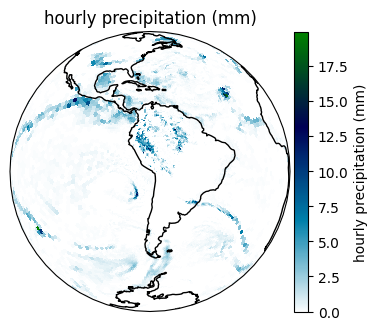

In [3]:
proj = ccrs.Orthographic(central_latitude=-17.5, central_longitude=-72.5)

# Create a time-varying precipitation
def create_plot(t):
    rain = rainc[t] + rainnc[t] - rainc[t-1] - rainnc[t-1]  # hourly precip = diff of accumulated totals between consecutive timesteps
    return rain.plot(projection=proj, 
                   rasterize=True, 
                   backend='matplotlib', 
                   pixel_ratio=4.0, 
                   clabel="hourly precipitation (mm)", 
                   features=['coastline'], 
                   width=300, height=200, 
                   cmap='ocean_r', 
                   title="hourly precipitation (mm)")
     
    
# Create a HoloMap with frames from 0 to 10
holomap = hv.HoloMap({t: create_plot(t) for t in range(1, n_time)}, kdims='Time')

# holomap is an interactive time-slider widget that needs a live kernel to scrub through
# frames, so it won't display outside Jupyter (e.g. on GitHub). Show one representative
# static frame here instead; see the saved MP4/GIF below for the full animation.
hv.render(create_plot(n_time // 2), backend='matplotlib')

#### save as MP4 and play

In [4]:
hv.save(holomap, 'prec.mp4', fmt='mp4', fps=10)
Video("prec.mp4", embed=True)  # embed=True inlines the video as base64 so it also plays on GitHub

#### To make your animation visible on GitHub, save animation as a .gif:

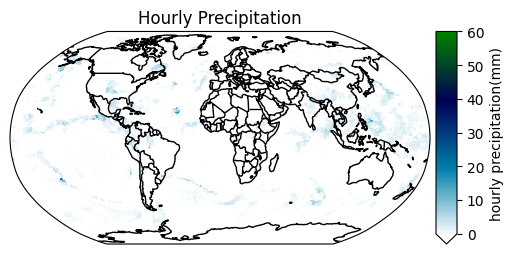

In [5]:
proj = ccrs.Robinson(central_longitude=-72.5)

# Create a time-varying precipitation
def create_plot(t):
    rain = rainc[t] + rainnc[t] - rainc[t-1] - rainnc[t-1]  # hourly precip = diff of accumulated totals between consecutive timesteps
    
    return rain.plot(height=200,
            width=450,
            clim=(0, 60),
            clabel="hourly precipitation(mm)",
            backend="matplotlib",
            cmap="ocean_r",
            projection=ccrs.Robinson(),
            features=["borders", "coastline"],
            title="Hourly Precipitation",
        )
     
    
# Create a HoloMap with frames from 0 to 10
holomap = hv.HoloMap({t: create_plot(t) for t in range(1, n_time)}, kdims='Time')

# Same as above: holomap is an interactive widget, so show one static frame here.
hv.render(create_plot(n_time // 2), backend='matplotlib')

In [6]:
hv.save(holomap, 'prec_robinson.gif', dpi=250, fmt='gif', fps=10)

![Hourly precipitation](prec_robinson.gif)